In [71]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [72]:
NSE=.2
EPS=200
ALP=.001
N_SMP=1000
TEST_SIZE=.2
rng=np.random.default_rng(seed=24)
params={
    'legend.fontsize':'medium',
    'figure.figsize':(15,6),
    'axes.labelsize':'medium',
    'axes.titlesize':'medium',
    'xticks.labelsize':'medium',
    'ytick.labelsize':'medium'
} 
    


In [73]:
X,y=datasets.make_moons(n_samples=N_SMP,
                       shuffle=True,
                       noise=NSE,
                       random_state=24)
X[:5],y[:5]

(array([[ 0.90633951,  0.90267624],
        [-1.11536828,  0.75579289],
        [ 1.88769158,  0.4175967 ],
        [-0.93345034, -0.02299851],
        [-0.96872877,  0.06396285]]),
 array([0, 0, 1, 0, 0]))

In [74]:
df = pd.DataFrame(X, columns = ['A','B'])
df['target'] = y
df.head()

,A,B,target
0,0.906340,0.902676,0
1,-1.115368,0.755793,0
2,1.887692,0.417597,1
3,-0.933450,-0.022999,0
4,-0.968729,0.063963,0


In [75]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   A       1000 non-null   float64
 1   B       1000 non-null   float64
 2   target  1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB


In [76]:
df.describe()

,A,B,target
count,1000.000000,1000.000000,1000.00000
mean,0.490841,0.239025,0.50000
std,0.898951,0.540082,0.50025
min,-1.688795,-0.955280,0.00000
25%,-0.149565,-0.205090,0.00000
50%,0.500100,0.241163,0.50000
75%,1.095048,0.680394,1.00000
max,2.419113,1.612075,1.00000


<Axes: xlabel='target'>

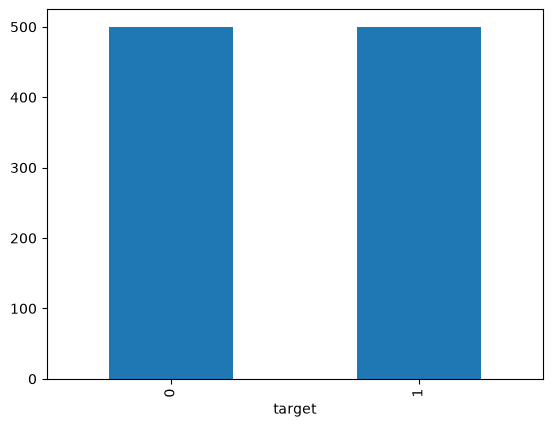

In [77]:
fig,ax=plt.subplots()
df['target'].value_counts().plot(ax=ax,kind='bar')

<Axes: xlabel='A', ylabel='B'>

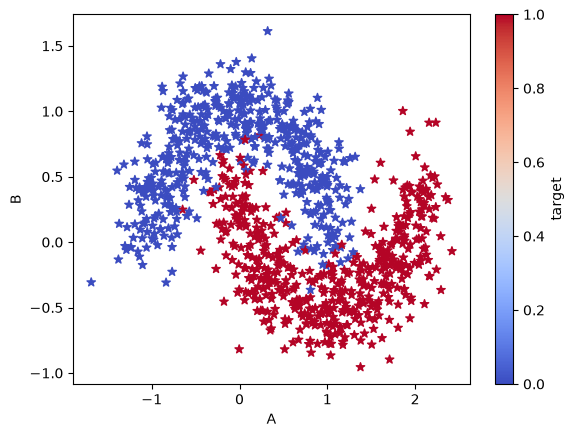

In [78]:
df.plot.scatter("A","B",s=40,marker='*',c='target',cmap='coolwarm')

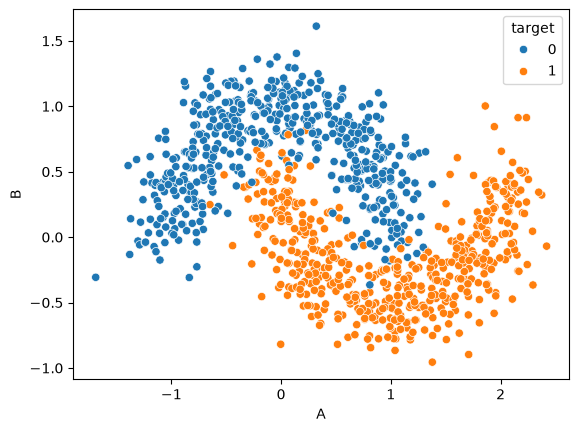

In [79]:
import seaborn as sns
ax=sns.scatterplot(x='A',y='B',data=df,hue='target')

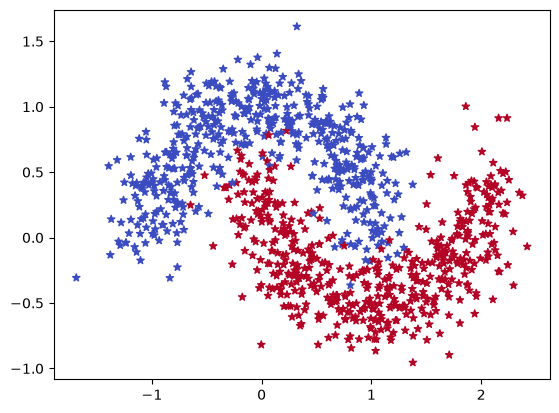

In [80]:
plt.figure()
plt.scatter(X[:,0],X[:,1],s=30,c=y,marker='*',cmap='coolwarm')

In [81]:
train,test=df.to_numpy()[:900],df.to_numpy()[900:]
print(train.shape,test.shape)

(900, 3) (100, 3)


In [82]:
def predict(row: np.ndarray,wgts: np.ndarray):
    z=wgts[0]
    for i in  range(len(row)-1):
        z+=wgts[i+1]*row[i]
    return 1 if z>=0 else 0

In [83]:
weight = np.array([0.1,2.0,1.0])
display(df.loc[0])
predict(df.loc[0].values, weight)

A         0.906340
B         0.902676
target    0.000000
Name: 0, dtype: float64

1

In [84]:
def train_weights(train: np.ndarray, alpha:float, n_epochs: int) -> tuple[list, np.ndarray]:
    errors = []
    weights = rng.random(train.shape[1])
    m = train.shape[0]

    for epoch in range(n_epochs):
        sum_error = 0.0
        for row in train:
            prediction = predict(row, weights)
            error = prediction - row[-1]
            sum_error += error**2
            weights[0] = weights[0] - alpha * error
            for i in range(len(row)-1):
                weights[i+1] = weights[i + 1] - alpha * error * row[i]
        errors.append(sum_error / m)
        if epoch % 10 == 0:
            print(f"Epoch {epoch:3d} : Loss = {errors[-1]:.4f}")
    return errors, weights

In [85]:
error, weight = train_weights(train, ALP,EPS)
display(weight)
error

Epoch   0 : Loss = 0.4400
Epoch  10 : Loss = 0.1778
Epoch  20 : Loss = 0.1778
Epoch  30 : Loss = 0.1756
Epoch  40 : Loss = 0.1722
Epoch  50 : Loss = 0.1800
Epoch  60 : Loss = 0.1756
Epoch  70 : Loss = 0.1756
Epoch  80 : Loss = 0.1778
Epoch  90 : Loss = 0.1711
Epoch 100 : Loss = 0.1733
Epoch 110 : Loss = 0.1867
Epoch 120 : Loss = 0.1711
Epoch 130 : Loss = 0.1822
Epoch 140 : Loss = 0.1733
Epoch 150 : Loss = 0.1756
Epoch 160 : Loss = 0.1756
Epoch 170 : Loss = 0.1800
Epoch 180 : Loss = 0.1800
Epoch 190 : Loss = 0.1844


array([-0.00073116,  0.00252746, -0.00400164])

[np.float64(0.44),
 np.float64(0.45222222222222225),
 np.float64(0.39444444444444443),
 np.float64(0.29777777777777775),
 np.float64(0.2),
 np.float64(0.14333333333333334),
 np.float64(0.16666666666666666),
 np.float64(0.17333333333333334),
 np.float64(0.18),
 np.float64(0.17555555555555555),
 np.float64(0.17777777777777778),
 np.float64(0.17777777777777778),
 np.float64(0.1688888888888889),
 np.float64(0.18222222222222223),
 np.float64(0.17333333333333334),
 np.float64(0.18222222222222223),
 np.float64(0.17333333333333334),
 np.float64(0.18222222222222223),
 np.float64(0.17555555555555555),
 np.float64(0.17555555555555555),
 np.float64(0.17777777777777778),
 np.float64(0.18444444444444444),
 np.float64(0.17555555555555555),
 np.float64(0.17555555555555555),
 np.float64(0.18666666666666668),
 np.float64(0.1711111111111111),
 np.float64(0.1711111111111111),
 np.float64(0.17555555555555555),
 np.float64(0.18),
 np.float64(0.17555555555555555),
 np.float64(0.17555555555555555),
 np.float6

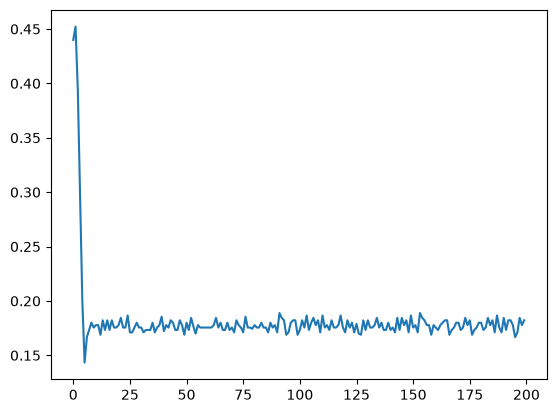

In [86]:
fig, ax = plt.subplots()
ax.plot(error)

In [87]:
prediction = []
for row in test:
    a = predict(row, weight)
    prediction.append(a)
accuracy_score(test[:, -1], prediction)

0.89

In [88]:
cm = confusion_matrix(test[:, -1], prediction)
cm

array([[54,  4],
       [ 7, 35]])

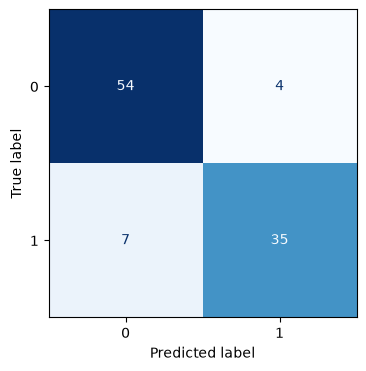

In [89]:
disp = ConfusionMatrixDisplay(confusion_matrix = cm, display_labels= [0,1])
fig, ax = plt.subplots(figsize = (4,4))
disp.plot(ax = ax, cmap = 'Blues', colorbar = False)


In [90]:
def plot_decision_boundary(X_tr, X_ts, wts):
    fig , ax = plt.subplots()
    dm = 0.01
    margin = 10*dm
    x_min, x_max = X_tr[:, 0].min() - margin, X_tr[:, 0].max() - margin
    y_min, y_max = X_tr[:, 1].min() - margin, X_tr[:, 1].max() - margin

    xx, yy = np.meshgrid(np.arange(x_min, x_max, dm),np.arange(y_min, y_max, dm))

    XX = np.c_[xx.ravel(), yy.ravel()]
    XX = np.hstack((XX, np.ones((XX.shape[0], 1))))
    y_pred = []

    for row in XX:
        a = predict(row, wts)
        y_pred.append(a)
    
    Z = np.array(y_pred).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=plt.cm.Paired, alpha=0.6)
    
    ax.scatter(X_tr[:, 0], X_tr[:, 1], c=X_tr[:, 2],
               s=30, edgecolors='k', cmap='coolwarm')
    
    ax.scatter(X_ts[:, 0], X_ts[:, 1], c=X_ts[:, 2],
               s=30, marker='*', edgecolors='k', cmap=plt.cm.seismic)


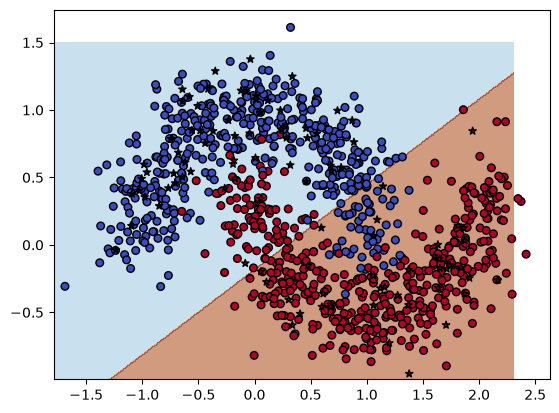

In [91]:
plot_decision_boundary(train,test,weight)

In [92]:
def fn_sigmoid(z):
    return 1/(1 + np.exp(-z))

In [93]:
fn_sigmoid(np.asarray([-np.inf, -1,0,+1, np.inf]))

array([0.        , 0.26894142, 0.5       , 0.73105858, 1.        ])

In [94]:
def predict(row: np.ndarray, wgts: np.ndarray):
    z = wgts[0]

    for i in range(len(row) - 1):
        z += wgts[i+1]*row[i]  # Aggregation function

    return fn_sigmoid(z)


In [95]:
def train_weights(train: np.ndarray, alpha: float, n_epochs: int
                  ) -> tuple[list, np.ndarray]:
    errors = [] # Collect all errors
    weights = rng.random(train.shape[1]) # Random generation
    m = train.shape[0] # num samples

    for epoch in range(n_epochs): # loop for number of epochs
        sum_error = 0.0
        for row in train:
            a = predict(row, weights)
            error = -row[-1]*np.log( a ) - ( 1 - row [-1] ) * (1-np.log( 1 - a )) # Note: See correction below
            dz = a - row[-1] # this is (dz = a-y)
            sum_error += error**2
            weights[0] = weights[0] - alpha * dz # adjusting weights
            for i in range(len(row)-1):
                weights[i + 1] = weights[i + 1] - alpha * dz * row[i] # adjusting weights
        errors.append(sum_error / m)
        if epoch % 10 == 0:
            print(f"Epoch {epoch:3d}: Loss = {errors[-1]:.4f}")
    return errors, weights


In [96]:
error, weight = train_weights(train, ALP,EPS)
display(weight)
error

Epoch   0: Loss = 2.3691
Epoch  10: Loss = 1.2333
Epoch  20: Loss = 1.1293
Epoch  30: Loss = 1.0992
Epoch  40: Loss = 1.0868
Epoch  50: Loss = 1.0817
Epoch  60: Loss = 1.0805
Epoch  70: Loss = 1.0815
Epoch  80: Loss = 1.0838
Epoch  90: Loss = 1.0869
Epoch 100: Loss = 1.0903
Epoch 110: Loss = 1.0939
Epoch 120: Loss = 1.0975
Epoch 130: Loss = 1.1011
Epoch 140: Loss = 1.1045
Epoch 150: Loss = 1.1078
Epoch 160: Loss = 1.1109
Epoch 170: Loss = 1.1138
Epoch 180: Loss = 1.1166
Epoch 190: Loss = 1.1192


array([ 0.42337501,  1.17645425, -4.28565901])

[np.float64(2.369146974852257),
 np.float64(2.0325227190387216),
 np.float64(1.7997837249081443),
 np.float64(1.6368929485577965),
 np.float64(1.5206817187615218),
 np.float64(1.4359136707176978),
 np.float64(1.372667429597173),
 np.float64(1.3244468151999371),
 np.float64(1.2869380887584796),
 np.float64(1.2572242699081346),
 np.float64(1.233293899137347),
 np.float64(1.213732630358168),
 np.float64(1.1975272430057928),
 np.float64(1.1839390760344397),
 np.float64(1.1724208340162086),
 np.float64(1.1625609088978937),
 np.float64(1.1540454556339141),
 np.float64(1.1466321230505647),
 np.float64(1.1401315676139452),
 np.float64(1.1343942501366955),
 np.float64(1.1293008746834148),
 np.float64(1.1247553755661786),
 np.float64(1.1206797116535434),
 np.float64(1.1170099591601932),
 np.float64(1.113693348618918),
 np.float64(1.1106859961626476),
 np.float64(1.1079511507610542),
 np.float64(1.105457828659513),
 np.float64(1.103179741085659),
 np.float64(1.1010944460049448),
 np.float64(1.099

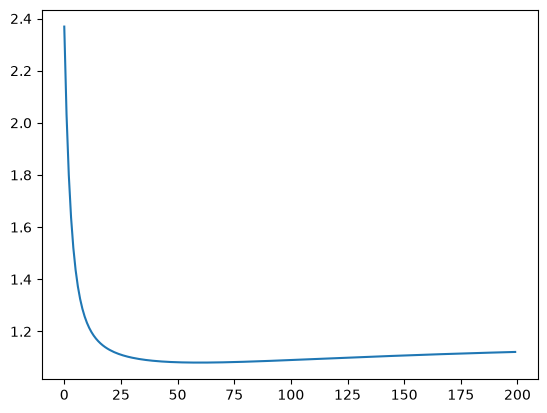

In [97]:
fig, ax = plt.subplots()
ax.plot(error)

In [99]:
prediction = []
for row in train:
    a = predict(row, weight)
    y_p = 1 if a >= 0.5 else 0
    prediction.append(y_p)
accuracy_score(train[:, -1], prediction)


0.8644444444444445